# When is a contradiction perceptual or symbolic?

A neuro-symbolic model reads concepts from images with a network and applies symbolic rules to them. When a pool of
labelled observations contradicts the rules, the cause can lie in the perception (an unstructured perception, or a
*reasoning shortcut* where the network reads the concepts consistently wrong) or in the symbolic theory (a wrong rule).
This notebook runs the diagnosis of the paper *When Is a Contradiction Perceptual or Symbolic? Identifiability in
Neuro-Symbolic Models* on the MNMath pools of its experiments, checks the conditions of its three propositions on
them, and applies its support check to pools with a rare cell.

The diagnosis compares the best explanation on each side, a *remapping of the concepts* against an *edit of a
rule*, each penalised by its prior, and reads the verdict in a penalised log-odds $\Lambda$ with a margin. A second
rule reading the same concepts serves as a control: a remapping must explain its observations too, an edit need not.

The `data/` folder holds the output of the perception on each pool (no network is needed to run this notebook):
for every observation, the softmax of the network on each of the four digits, the true digits, and the labels of the
two rules. `helper.py` loads the pools and enumerates the two families. The score, the verdict and the conditions are
written below.

In [1]:
import math, numpy as np, matplotlib.pyplot as plt
from helper import (CELLS, RULES, T0, LOG_M, IDENTITY, POOLS, load_pool, remappings, alpha_name, edits, edit_priors,
                    diff_cells, translate, read_cells, read_index, cell_mass, preimages, counts, identity_lemma,
                    thin, show)

## 1. The pool and the two families of hypotheses

MNMath (from the rsbench suite) shows four handwritten digits $a, b, c, d$ restricted to the classes $\{0, 1, 2\}$ and
two rules: the *control* rule $y_0 = 2a + b$, never edited, and the *edited* rule $y_1 = c + d$, the one the
edits touch (the names of the edits write its two digits $a$ and $b$). The same network reads each digit separately,
so the perception is factorised: its distribution over a *cell* $(a, b)$ is the product of its distributions over the
two positions.

* $\mathcal{M}$: every map $\hat\alpha : G \to G$ of the three classes, identity included, $|\mathcal{M}| = 27$. Under
  hypothesis $\hat\alpha$ the network reads $\hat\alpha(g)$ when the true concept is $g$; a permutation is a
  reasoning shortcut, a non-injective map a *collapse*. Uniform prior, $-\log P(\alpha \mid H_0) = \log 27$.
* $\mathcal{U}$: the candidate edits of the edited rule, in four families: replacing the law by another (8 laws),
  guarding one row or one column of the table with another law, patching a single cell. Prior
  $L(T) = \log(\text{nominal size of the family}) + \log Z$, normalised over $\mathcal{U}$.

In [2]:
ALPHAS = remappings(); U = edits(); L_U, Z = edit_priors(U)
EDITS = list(U); PRIOR_U = np.array([L_U[n] for n in EDITS])
DIFF = diff_cells(U)     # [|U|, 9]: the cells each edit changes
print(f"{len(ALPHAS)} remappings (prior log|M| = {LOG_M:.2f} nats each), {len(U)} edits, Z = {Z:.3f}")
families = {}
for n, (f, _) in U.items(): families.setdefault(f, []).append(n)
for f, names in families.items():
    print(f"  {f:13s} {len(names):3d} edits   L(T) = {L_U[names[0]]:.2f} nats   e.g. {names[0]}")
p, c, y, meta = load_pool(POOLS["clean"])
print(f"\nclean pool: p {p.shape} (observations, positions, classes), c {c.shape}, y {y.shape}; cause: {meta['cause']}")

27 remappings (prior log|M| = 3.30 nats each), 84 edits, Z = 3.667
  replacement     8 edits   L(T) = 3.38 nats   e.g. replace by a*b
  guard row      20 edits   L(T) = 4.48 nats   e.g. if a=0: a*b
  guard column   20 edits   L(T) = 4.48 nats   e.g. if b=0: a*b
  patch          36 edits   L(T) = 4.88 nats   e.g. patch (0,0)->1

clean pool: p (300, 4, 3) (observations, positions, classes), c (300, 4), y (300, 2); cause: none


## 2. The contradiction score

For observation $i$ under hypothesis $(\alpha, T)$, the mass the network puts on each reading is brought back to the
true concepts by $\alpha$ (shared equally among the concepts that produce the reading, `translate`), and the
*contradiction score* is minus the log of the mass that lands on cells $T$ maps to the observed label, with a floor
$\kappa$ that stands for uniform label noise:

$$ s_i(\alpha, T) = -\log\Big( (1 - |Y|\kappa)\, P_i(\alpha, T) + \kappa \Big), \qquad
   P_i(\alpha, T) = \sum_{c \,:\, T(c) = y_i} p_\alpha(c \mid x_i). $$

The sum $\sum_i s_i$ runs over every (observation, rule) pair. Without the floor a confident reading that the theory
contradicts would cost $+\infty$; with it, it costs at most $-\log\kappa$. The experiments use $\kappa = 10^{-3}$.

In [3]:
KAPPA = 1e-3

def score(p, y, alpha, T, rule, kappa=KAPPA):
    # s_i(alpha, T) on one rule, for every observation
    i, j = RULES[rule]["pos"]; Y = RULES[rule]["Y"]
    qa, _ = translate(p[:, i], alpha); qb, _ = translate(p[:, j], alpha)
    joint = qa[:, :, None] * qb[:, None, :]                              # [N, 3, 3] mass brought back to each true cell
    M = np.zeros((3, 3, Y))
    for a, b in CELLS: M[a, b, T(a, b)] = 1                              # the table of T
    p_y = np.einsum("iab,aby->iy", joint, M)                             # [N, Y] mass of the cells T maps to each label
    P = p_y[np.arange(len(y)), y[:, RULES[rule]["col"]]]                 # the mass compatible with the observed label
    return -np.log((1 - Y * kappa) * P + kappa)

s = score(p, y, IDENTITY, T0["edited"], "edited")
print(f"clean pool, edited rule, identity and T0: mean score {s.mean():.3f} nats, max {s.max():.2f}")

clean pool, edited rule, identity and T0: mean score 0.036 nats, max 1.43


## 3. The verdict

Each side keeps its best hypothesis, penalised by its prior:

$$ \Lambda(D) = \Big[ -\sum_i s_i(\mathrm{id}, T^\star) - L(T^\star) \Big] - \Big[ -\sum_i s_i(\alpha^\star, T_0) - \log|\mathcal{M}| \Big]. $$

With the margin $m = \log|\mathcal{M}|$, $\Lambda$ gives four verdicts: *revise the theory* by $T^\star$ if
$\Lambda > m$; if $\Lambda < -m$, *revise the perception* by $\alpha^\star$ when $\alpha^\star \ne \mathrm{id}$ and
*no structural repair* when $\alpha^\star = \mathrm{id}$; *undecidable* if $|\Lambda| \le m$. No structural repair
means that neither family supports one: it is the verdict of a healthy system and of an unstructured perception.

An edit is a candidate only if it differs from $T_0$ on a *populated* cell, a cell in which an observation is read
(the support requirement of the paper). Every cell of the sixteen pools below is populated, and the requirement comes
into play in section 8.

In [4]:
def score_tables(p, y):
    # per observation, the score summed over the two rules:
    # S0 [N, |M|] under each (alpha, T0), S1 [N, |U|] under each (id, T)
    S0 = np.stack([sum(score(p, y, a, T0[r], r) for r in RULES) for a in ALPHAS], 1)
    s_control = score(p, y, IDENTITY, T0["control"], "control")     # an edit leaves the control rule as it is
    S1 = np.stack([s_control + score(p, y, IDENTITY, fn, "edited") for _, fn in U.values()], 1)
    return S0, S1

def verdict(S0, S1, read):
    # read [N]: the cell each observation reads on the edited rule, as an index in CELLS
    cost_H0 = S0.sum(0) + LOG_M
    populated = np.bincount(read, minlength=len(CELLS)) > 0
    cost_H1 = np.where((DIFF & populated).any(1), S1.sum(0) + PRIOR_U, np.inf)          # the support requirement
    a, t = int(cost_H0.argmin()), int(cost_H1.argmin()); lam = float(cost_H0[a] - cost_H1[t])
    if lam > LOG_M: v = "revise the theory"
    elif lam < -LOG_M: v = "revise the perception" if ALPHAS[a] != IDENTITY else "no structural repair"
    else: v = "undecidable"
    return dict(log_odds=lam, alpha=alpha_name(ALPHAS[a]), edit=EDITS[t], verdict=v)

def diagnose(p, y):
    return verdict(*score_tables(p, y), read_index(p, "edited"))

PAPER = {"clean": -170.4, "shortcut 1<->2": -2736.7, "dense a*b": 1436.0,
         "local (a+b) mod 3": 645.4, "exception a=2": 362.8,
         "one digit 10%": -142.8, "one digit 20%": -115.9, "one digit 50%": -21.6,
         "one digit 70%": 66.5, "one digit 100%": 519.2,
         "two digits 10%": -139.6, "two digits 20%": -107.5, "two digits 50%": -3.7,
         "two digits 70%": 60.9, "two digits 100%": 355.6, "collapse 2->1": -1601.0}
results = {}
for name, file in POOLS.items():
    p, c, y, meta = load_pool(file); r = diagnose(p, y); r.update(pool=name, paper=PAPER[name]); results[name] = r
show(list(results.values()), ["pool", "log_odds", "paper", "verdict", "alpha", "edit"],
     {"log_odds": "{:+.1f}", "paper": "{:+.1f}"})
assert all(abs(r["log_odds"] - r["paper"]) < 0.1 for r in results.values()), "a value differs from the paper"

pool               log_odds  paper    verdict                alpha     edit              
clean              -170.4    -170.4   no structural repair   012->012  if a=1: (a+b)%3   
shortcut 1<->2     -2736.7   -2736.7  revise the perception  012->021  patch (1,1)->4    
dense a*b          +1436.0   +1436.0  revise the theory      012->012  replace by a*b    
local (a+b) mod 3  +645.4    +645.4   revise the theory      012->012  replace by (a+b)%3
exception a=2      +362.8    +362.8   revise the theory      012->012  if a=2: a*b       
one digit 10%      -142.8    -142.8   no structural repair   012->012  patch (2,1)->2    
one digit 20%      -115.9    -115.9   no structural repair   012->012  patch (2,1)->4    
one digit 50%      -21.6     -21.6    no structural repair   012->012  patch (0,1)->2    
one digit 70%      +66.5     +66.5    revise the theory      012->012  if a=2: a*b       
one digit 100%     +519.2    +519.2   revise the theory      012->012  replace by a+b+1  
two digits

The seven pools of the paper return the expected verdict with the expected hypothesis: no structural repair on the
clean pool, the swap $1 \leftrightarrow 2$ on the shortcut pool, the true edit on the three symbolic pools. The
corrupted pools (one or two digits replaced by another class on a share $\rho$ of the observations) return no
structural repair up to 50% and flip to *revise the theory* between 50 and 70%, where the corruption becomes cheaper
to explain as a rule. The collapse pool, where the network reads the digits 1 and 2 both as 1, returns the collapse
$012 \to 011$. Where the perception side wins, the column `edit` shows the best losing edit.

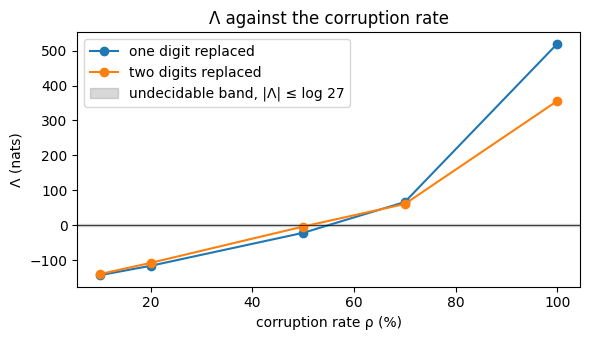

In [5]:
rates = [10, 20, 50, 70, 100]
plt.figure(figsize=(6, 3.5))
for fam, label in (("one digit", "one digit replaced"), ("two digits", "two digits replaced")):
    plt.plot(rates, [results[f"{fam} {r}%"]["log_odds"] for r in rates], "o-", label=label)
plt.axhspan(-LOG_M, LOG_M, color="grey", alpha=0.3, label="undecidable band, |Λ| ≤ log 27")
plt.axhline(0, color="k", lw=0.5); plt.xlabel("corruption rate ρ (%)"); plt.ylabel("Λ (nats)")
plt.legend(); plt.title("Λ against the corruption rate"); plt.tight_layout(); plt.show()

## 4. The quantities of the count conditions

The three propositions of the paper give, for each cause, a sufficient condition under which $\Lambda$ returns it.
Each condition is an inequality on counts of observations, read on the pool with its concept labels:

* an observation is *confident* if it puts a mass $\ge 1 - \delta$ on the cell it reads, for a threshold $\delta$,
  and *hesitating* otherwise; it is *read correctly* if the cell it reads is its true cell and *misread*
  otherwise; it is *sane* if it is read correctly and its label follows $T_0$;
* three constants follow from the floor $\kappa$ and the threshold $\delta$:
  $\varepsilon = -\log((1 - |Y|\kappa)(1 - \delta) + \kappa)$, the most a confident observation costs when the theory
  is right on its cell, $\zeta = -\log(\delta + \kappa)$, the least it costs when the theory is wrong, and
  $\bar\zeta = -\log\kappa$, the most any observation costs.

The results hold for every $\delta$, so each condition is evaluated at the $\delta$ of a small grid that gives it the
largest *slack*, its left-hand side minus its right-hand side, in nats. The condition holds when the slack is
positive.

In [6]:
DELTAS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1]
ZETA_BAR = -math.log(KAPPA)

def constants(delta, kappa=KAPPA):
    Ys = [r["Y"] for r in RULES.values()]
    eps = max(-math.log((1 - Y * kappa) * (1 - delta) + kappa) for Y in Ys)         # the larger of the two rules
    zeta = -math.log(delta + kappa); gamma = max(math.log(1 + delta / kappa), eps)   # gamma: used by Proposition 3
    return zeta, eps, gamma

def best_delta(condition):
    return max((condition(d) for d in DELTAS), key=lambda r: r["slack"])

for d in (1e-3, 1e-2):
    print("delta = {:g}: zeta = {:.2f}, epsilon = {:.4f}, gamma = {:.2f}; zeta_bar = {:.2f}"
          .format(d, *constants(d), ZETA_BAR))

delta = 0.001: zeta = 6.21, epsilon = 0.0070, gamma = 0.69; zeta_bar = 6.91
delta = 0.01: zeta = 4.51, epsilon = 0.0161, gamma = 2.40; zeta_bar = 6.91


## 5. Proposition 1: a wrong rule

On a pool whose labels follow another rule $T_1 \in \mathcal{U}$ on the edited rule, $\Lambda > m$ as soon as, for
every remapping $\alpha$, the identity included,

$$ N_\alpha\, \zeta \;>\; N \varepsilon + L(T_1) + C_h^{T_1} + N^{\mathrm{mis}}\, \bar\zeta . $$

$N_\alpha$ counts, over both rules, the confident observations read correctly that $(\alpha, T_0)$ leaves
contradicted: none of the preimages of their read cell under $\alpha$ carries the observed label. $C_h^{T_1}$ is the
cost of the hesitating observations under $(\mathrm{id}, T_1)$ and $N^{\mathrm{mis}}$ the number of confident misread
ones, each charged $\bar\zeta$, so that a real perception is admitted. The prior of $\alpha$ and the margin cancel.
For $\alpha = \mathrm{id}$ the condition asks that $T_1$ beat $T_0$, and for the other remappings that none repair
the pool as cheaply as $T_1$.

In [7]:
TRUE_EDIT = {"dense a*b": "replace by a*b", "local (a+b) mod 3": "replace by (a+b)%3", "exception a=2": "if a=2: a*b"}

def prop1_slack(p, c, y, T1_name, delta, kappa=KAPPA):
    zeta, eps, _ = constants(delta, kappa); N = 2 * len(y); Na = np.zeros(len(ALPHAS), int); Ch1 = 0.0; Nmis = 0
    T1 = U[T1_name][1]                                                                  # the rule the labels follow
    for r in RULES:
        rc, mass = read_cells(p, r); conf = mass >= 1 - delta; yo = y[:, RULES[r]["col"]]
        okread = (rc == c[:, list(RULES[r]["pos"])]).all(1)                             # read correctly
        Ch1 += score(p, y, IDENTITY, T1 if r == "edited" else T0[r], r, kappa)[~conf].sum()   # hesitating, under T1
        Nmis += int((conf & ~okread).sum())                                             # confident, misread
        for ai, alpha in enumerate(ALPHAS):
            repaired = np.array([any(T0[r](*cp) == yo[i] for cp in preimages(alpha, tuple(rc[i])))
                                 for i in range(len(y))])
            Na[ai] += int((conf & okread & ~repaired).sum())
    ia = int(Na.argmin())
    return dict(delta=delta, N_alpha_min=int(Na[ia]), worst_alpha=alpha_name(ALPHAS[ia]), L_T1=L_U[T1_name],
                C_h_T1=Ch1, N_mis=Nmis, slack=Na[ia] * zeta - (N * eps + L_U[T1_name] + Ch1 + Nmis * ZETA_BAR))

rows = []
for name, T1_name in TRUE_EDIT.items():
    p, c, y, _ = load_pool(POOLS[name]); b = best_delta(lambda d: prop1_slack(p, c, y, T1_name, d))
    b.update(pool=name, log_odds=results[name]["log_odds"], T_star=results[name]["edit"], holds=b["slack"] > 0)
    rows.append(b)
show(rows, ["pool", "log_odds", "T_star", "delta", "N_alpha_min", "worst_alpha", "L_T1", "C_h_T1", "N_mis",
            "slack", "holds"],
     {"log_odds": "{:+.1f}", "delta": "{:g}", "L_T1": "{:.2f}", "C_h_T1": "{:.1f}", "slack": "{:+.1f}"})
assert all(results[name]["edit"] == T1_name for name, T1_name in TRUE_EDIT.items()), "T* is not the rule of the pool"

pool               log_odds  T_star              delta  N_alpha_min  worst_alpha  L_T1  C_h_T1  N_mis  slack   holds
dense a*b          +1436.0   replace by a*b      0.01   179          012->012     3.38  22.3    1      +765.0  True 
local (a+b) mod 3  +645.4    replace by (a+b)%3  0.01   67           012->012     3.38  23.3    1      +258.9  True 
exception a=2      +362.8    if a=2: a*b         0.01   45           012->012     4.48  21.5    1      +160.5  True 


The condition holds on the three pools, and the remapping that leaves the fewest observations contradicted is the
identity. The edit $T^\star$ that the verdict returns is the rule the labels follow, so the inequality checked here is
the one of the rule certificate of the paper, which takes $T_1 := T^\star$.

## 6. Proposition 2: a reasoning shortcut

On a pool read through $\alpha_0 \ne \mathrm{id}$ on every position, $\Lambda < -m$ with $\alpha^\star \ne \mathrm{id}$
as soon as

$$ N^{\mathrm{viol}}_{\neg}\, \zeta \;>\; N \varepsilon + \sum_i \log K_i + N^{\mathrm{mis}}_{\alpha_0}\, \bar\zeta + C_h^{\alpha_0} + 2 \log|\mathcal{M}| . $$

$N^{\mathrm{viol}}_{\neg}$ counts, on the control rule, the confident observations that follow $\alpha_0$ and whose
read cell contradicts their label: an edit of the edited rule cannot repair them, and each costs it at least $\zeta$.
$K_i$ is the number of cells $\alpha_0$ sends to the read cell of observation $i$, $1$ for a permutation and the price
of the ambiguity for a collapse. $N^{\mathrm{mis}}_{\alpha_0}$ is the number of confident observations read elsewhere
than $\alpha_0(c_i)$, each charged $\bar\zeta$, and $C_h^{\alpha_0}$ the cost of the hesitating ones under $\alpha_0$.

The proposition also asks that $\alpha_0$ change the labels of the control rule on a cell that is the true cell of an
observation (the condition on the control of the paper). A positive $N^{\mathrm{viol}}_{\neg}$ shows that it does.

In [8]:
def prop2_slack(p, c, y, alpha0, delta, kappa=KAPPA):
    zeta, eps, _ = constants(delta, kappa); N = 2 * len(y)
    conf, follows, sum_log_K, Nmis0, Ch0 = {}, {}, 0.0, 0, 0.0
    for r in RULES:
        rc, mass = read_cells(p, r); conf[r] = mass >= 1 - delta; true = c[:, list(RULES[r]["pos"])]
        follows[r] = (rc == np.vectorize(lambda t: alpha0[t])(true)).all(1)  # the reading is alpha0 of the true cell
        sum_log_K += sum(math.log(len(preimages(alpha0, tuple(rc[i])))) for i in np.where(conf[r])[0])
        Nmis0 += int((conf[r] & ~follows[r]).sum()); Ch0 += score(p, y, alpha0, T0[r], r, kappa)[~conf[r]].sum()
    rc, _ = read_cells(p, "control"); yo = y[:, RULES["control"]["col"]]
    Nviol = int(sum(1 for i in np.where(conf["control"] & follows["control"])[0] if T0["control"](*rc[i]) != yo[i]))
    return dict(delta=delta, N_viol=Nviol, sum_log_K=sum_log_K, N_mis_alpha0=Nmis0, C_h=Ch0,
                slack=Nviol * zeta - (N * eps + sum_log_K + Nmis0 * ZETA_BAR + Ch0 + 2 * LOG_M))

rows = []
for name, alpha0 in (("shortcut 1<->2", (0, 2, 1)), ("collapse 2->1", (0, 1, 1))):
    p, c, y, _ = load_pool(POOLS[name]); b = best_delta(lambda d: prop2_slack(p, c, y, alpha0, d))
    b.update(pool=name, alpha0=alpha_name(alpha0), log_odds=results[name]["log_odds"],
             alpha_star=results[name]["alpha"], holds=b["slack"] > 0)
    rows.append(b)
show(rows, ["pool", "alpha0", "log_odds", "alpha_star", "delta", "N_viol", "sum_log_K", "N_mis_alpha0", "C_h",
            "slack", "holds"],
     {"log_odds": "{:+.1f}", "delta": "{:g}", "sum_log_K": "{:.1f}", "C_h": "{:.1f}", "slack": "{:+.1f}"})

pool            alpha0    log_odds  alpha_star  delta  N_viol  sum_log_K  N_mis_alpha0  C_h    slack   holds
shortcut 1<->2  012->021  -2736.7   012->021    0.01   207     0.0        0             29.0   +888.3  True 
collapse 2->1   012->011  -1601.0   012->011    0.001  117     434.6      0             117.3  +164.4  True 


The condition holds on both pools, and the verdict returns $\alpha^\star = \alpha_0$. The collapse pays
$\sum_i \log K_i$, $\log 2$ for every position read as the merged digit, even though it is the true cause: its slack
is five times smaller than the swap's.

## 7. Proposition 3: an unstructured perception

On a pool whose labels follow $T_0$ on every rule and whose misread observations follow no remapping, $\Lambda < -m$
with $\alpha^\star = \mathrm{id}$ under two conditions. The first is checked cell by cell on the edited rule, with the
following quantities:

* $N_c^{\mathrm{sane}}$ and $N_c^{\mathrm{mis}}$, the confident sane and the confident misread observations read in
  cell $c$;
* $q_c$, the largest share of a single label other than $T_0(c)$ among the misread ones, so that
  $q_c N_c^{\mathrm{mis}}$ is the most an edit of $c$ can recover;
* $C_h(c)$, the cost under $T_0$ of the hesitating observations read in $c$;
* the *leak* $\theta_c = \sum_{i \text{ read outside } c} \log(1 + \mu_i(c) / (P_i(T_0) + \kappa'))$ toward $c$ of the
  observations read elsewhere, with $\mu_i(c)$ the mass observation $i$ puts on $c$ and
  $\kappa' = \kappa / (1 - |Y|\kappa)$, and $\theta_\varnothing$ the sum of the $\theta_c$ of the unpopulated cells;
* $\gamma = \max(\log(1 + \delta/\kappa), \varepsilon)$, the most a confident misread observation can gain from an edit
  that does not recover it.

For every populated cell $c$:

$$ \underbrace{N_c^{\mathrm{sane}} (\zeta - \varepsilon)}_{\text{breakage}} \;-\; \underbrace{q_c N_c^{\mathrm{mis}} \zeta}_{\text{recovery}}
   \;>\; \underbrace{N_c^{\mathrm{mis}} \gamma + C_h(c) + \theta_c}_{\text{costs of the cell}} \;+\; \theta_\varnothing + 2 \log|\mathcal{M}| . $$

The second is Lemma 1 of the paper, which asks the same of every remapping $\alpha \ne \mathrm{id}$: the sane
observations it breaks must outweigh the misread ones it could repair (`identity_lemma` in `helper.py`). The slack
reported is the smaller of the two.

In [9]:
def prop3_slack(p, c, y, delta, kappa=KAPPA):
    zeta, eps, gamma = constants(delta, kappa); rules = list(RULES)
    Ns, Nm, q_c, conf = counts(p, c, y, delta)                                          # per (rule, cell)
    s_id = {r: score(p, y, IDENTITY, T0[r], r, kappa) for r in rules}
    J, P, ridx, kp, Ch = {}, {}, {}, {}, np.zeros((2, 9))
    for ri, r in enumerate(rules):
        J[r] = cell_mass(p, r); yo = y[:, RULES[r]["col"]]
        compatible = np.array([[T0[r](*cell) == yy for cell in CELLS] for yy in yo])
        P[r] = (J[r] * compatible).sum(1)                                               # mass compatible under T0
        ridx[r] = read_index(p, r); kp[r] = kappa / (1 - RULES[r]["Y"] * kappa)
        for k in range(9): Ch[ri, k] = s_id[r][~conf[ri] & (ridx[r] == k)].sum()
    e = "edited"                                                                        # its cells carry the condition
    leak = np.log(1 + J[e] / (P[e][:, None] + kp[e]))                                   # [N, 9] leak toward each cell
    theta_c = np.array([leak[ridx[e] != k, k].sum() for k in range(9)])
    populated = [k for k in range(9) if (ridx[e] == k).any()]
    theta_empty = sum(theta_c[k] for k in range(9) if k not in populated)
    bracket = Ns[1] * (zeta - eps) - q_c[1] * Nm[1] * zeta - Nm[1] * gamma - Ch[1]
    per_cell = min(bracket[k] - theta_c[k] - theta_empty - 2 * LOG_M for k in populated)
    lemma, worst = identity_lemma(Ns, Nm, q_c, Ch, J, P, kp, ridx, zeta, eps, gamma)
    return dict(delta=delta, N_sane=int(Ns.sum()), N_mis=int(Nm.sum()), q=q_c.max(), per_cell=per_cell, lemma=lemma,
                worst_alpha=worst, slack=min(per_cell, lemma))

rows = []
for name in ["clean"] + [f"{w} {r}%" for w in ("one digit", "two digits") for r in (10, 20, 50)]:
    p, c, y, _ = load_pool(POOLS[name]); b = best_delta(lambda d: prop3_slack(p, c, y, d))
    b.update(pool=name, holds=b["slack"] > 0, log_odds=results[name]["log_odds"]); rows.append(b)
show(rows, ["pool", "log_odds", "delta", "N_sane", "N_mis", "q", "per_cell", "lemma", "worst_alpha", "slack", "holds"],
     {"log_odds": "{:+.1f}", "delta": "{:g}", "q": "{:.2f}", "per_cell": "{:+.1f}", "lemma": "{:+.1f}",
      "slack": "{:+.1f}"})

pool            log_odds  delta  N_sane  N_mis  q     per_cell  lemma    worst_alpha  slack   holds
clean           -170.4    0.01   488     1      1.00  +72.9     +1064.2  012->010     +72.9   True 
one digit 10%   -142.8    0.01   462     27     1.00  +36.4     +907.9   012->010     +36.4   True 
one digit 20%   -115.9    0.01   442     50     1.00  +4.7      +689.2   012->011     +4.7    True 
one digit 50%   -21.6     0.01   370     120    1.00  -101.9    +189.0   012->010     -101.9  False
two digits 10%  -139.6    0.01   462     22     1.00  +28.0     +870.4   012->010     +28.0   True 
two digits 20%  -107.5    0.01   442     49     1.00  -12.4     +675.4   012->010     -12.4   False
two digits 50%  -3.7      0.003  287     88     0.75  -135.9    +120.4   012->010     -135.9  False


The condition holds on the clean pool and up to 20% of corruption on the one-digit pool (10% on the two-digit pool),
while the verdict stays correct up to 50%: the condition is sufficient and conservative. What costs the most is inside
the cell, where the recovered observations are credited with the maximal score and the hesitating ones pay their whole
score.

## 8. Rare cells and the support check

The condition of Proposition 3 is per cell, and a cell with few correct readings is where an edit is cheapest: a patch
of that cell breaks almost nothing and absorbs the misread observations that land there. To measure what this does to
the verdict, we thin one cell at a time, as in the paper. In each of the seven pools of its main table and for each of
the nine cells of the edited rule, we keep only $k$ of the observations whose true cell is that cell, the rest of the
pool unchanged, with one draw at $k = 0$ and three at $k = 1, 2, 5$ (90 diagnostics per pool).

The *support check* reads the perception only. The *support* of an edit $T$ is the number of observations whose
most likely reading on the edited rule falls in a cell where $T$ differs from $T_0$, and $\bar n$ is the median number
of readings per cell, empty cells included. When the verdict is *revise the theory* and the support of $T^\star$ is
below $\varphi\, \bar n$, with $\varphi = 2/3$, the verdict returned is *undecidable*.

A verdict is counted right when it is the one the pool calls for: no structural repair on the clean pool and on the
two corrupted pools, revise the perception on the shortcut pool, revise the theory on the three symbolic pools. Each
entry below reads right / undecidable / wrong.

In [10]:
PHI = 2 / 3; KS = (0, 1, 2, 5)
# the seven pools of the paper, with the verdict each calls for
SEVEN = {"clean": "no structural repair", "one digit 20%": "no structural repair",
         "two digits 20%": "no structural repair", "shortcut 1<->2": "revise the perception",
         "dense a*b": "revise the theory", "local (a+b) mod 3": "revise the theory",
         "exception a=2": "revise the theory"}

def support_check(r, read):
    # r: a result of `verdict`; read: the cell each observation reads on the edited rule
    n = np.bincount(read, minlength=len(CELLS)); support = DIFF[EDITS.index(r["edit"])] @ n
    return "undecidable" if r["verdict"] == "revise the theory" and support < PHI * np.median(n) else r["verdict"]

runs = []
for name, expected in SEVEN.items():
    p, c, y, _ = load_pool(POOLS[name]); S0, S1 = score_tables(p, y); read = read_index(p, "edited")
    for cell in CELLS:
        for k in KS:
            for seed in (range(3) if k > 0 else [0]):
                keep = thin(c, cell, k, seed); r = verdict(S0[keep], S1[keep], read[keep])
                runs.append(dict(pool=name, k=k, expected=expected, plain=r["verdict"],
                                 checked=support_check(r, read[keep])))

def tally(sel, key):
    right = sum(r[key] == r["expected"] for r in sel); undecidable = sum(r[key] == "undecidable" for r in sel)
    return f"{right}/{undecidable}/{len(sel) - right - undecidable}"

PAPER_RARE = {"clean": ("6/3/0", "27/0/0", "27/0/0", "27/0/0", "87/3/0"),
              "one digit 20%": ("0/0/9", "0/0/27", "0/5/22", "18/4/5", "18/72/0"),
              "two digits 20%": ("0/0/9", "0/3/24", "3/4/20", "12/5/10", "15/75/0"),
              **{name: ("9/0/0", "27/0/0", "27/0/0", "27/0/0", "90/0/0")
                 for name in ("shortcut 1<->2", "dense a*b", "local (a+b) mod 3", "exception a=2")}}
cols = [f"k = {k}" for k in KS] + ["with the check"]; table = []
for name in SEVEN:
    sel = [r for r in runs if r["pool"] == name]
    table.append({"pool": name, **{f"k = {k}": tally([r for r in sel if r["k"] == k], "plain") for k in KS},
                  "with the check": tally(sel, "checked")})
show(table, ["pool"] + cols)
assert all(tuple(t[k] for k in cols) == PAPER_RARE[t["pool"]] for t in table), "a count differs from the paper"
wrong = lambda key: sum(r[key] not in (r["expected"], "undecidable") for r in runs)
lost = sum(r["plain"] == r["expected"] != r["checked"] for r in runs)
print(f"\n{len(runs)} diagnostics: {wrong('plain')} wrong verdicts without the check, {wrong('checked')} with it; "
      f"right verdicts lost to the check: {lost}")

pool               k = 0  k = 1   k = 2   k = 5    with the check
clean              6/3/0  27/0/0  27/0/0  27/0/0   87/3/0        
one digit 20%      0/0/9  0/0/27  0/5/22  18/4/5   18/72/0       
two digits 20%     0/0/9  0/3/24  3/4/20  12/5/10  15/75/0       
shortcut 1<->2     9/0/0  27/0/0  27/0/0  27/0/0   90/0/0        
dense a*b          9/0/0  27/0/0  27/0/0  27/0/0   90/0/0        
local (a+b) mod 3  9/0/0  27/0/0  27/0/0  27/0/0   90/0/0        
exception a=2      9/0/0  27/0/0  27/0/0  27/0/0   90/0/0        

630 diagnostics: 126 wrong verdicts without the check, 0 with it; right verdicts lost to the check: 0


Without the check, the two corrupted pools are wrong or undecidable on every draw at $k \le 1$ and still err at
$k = 5$: misread observations from other cells land in the thinned cell, and a patch of that cell absorbs them. The
clean pool abstains on three of the nine empty cells. The shortcut and symbolic pools stay right even with the cell
empty, since the control rule and the many violating observations carry the verdict. With the check, every wrong
verdict becomes undecidable and no right verdict is lost.

These pools are at $\rho = 20\%$. The support of a wrong patch grows with the corruption rate while $\bar n$ does not,
and the paper reports what the check leaves at 40%, on five digits and on Kand-Logic.

## What is not in this notebook

The second domain, Kand-Logic, is in `kand_logic.ipynb`. The other experiments of the paper are not part of this
repository: the training of the perceptions and the construction of the pools, whose output is in `data/`, the
five-digit and ten-digit versions, the learned shortcuts, the baselines (paired control, edit-only, safe abductive
learning), the Bayes factor, the validation-based selection, the check on a labelled sample and the rare cells at
other corruption rates and in the other domains. Their code is available from the authors on request.